In [1]:
!pip install wordcloud
!pip install stopwords

In [2]:
import pandas as pd

# Load the preprocessed recipe dataset
df = pd.read_csv("preprocessed_recipes.csv")

# Show basic info and head
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231636 entries, 0 to 231635
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   input_text  231636 non-null  object
 1   steps_text  231636 non-null  object
dtypes: object(2)
memory usage: 3.5+ MB


,input_text,steps_text
0,winter squash mexican seasoning mixed spice ho...,make a choice and proceed with recipe dependin...
1,prepared pizza crust sausage patty eggs milk s...,preheat oven to 425 degrees f press dough into...
2,ground beef yellow onions diced tomatoes tomat...,brown ground beef in large pot add chopped oni...
3,spreadable cheese with garlic and herbs new po...,place potatoes in a large pot of lightly salte...
4,tomato juice apple cider vinegar sugar salt pe...,"mix all ingredients& boil for 2 1 / 2 hours , ..."


In [5]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from collections import Counter
import re

# Ensure nltk stopwords are available
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Clean text function
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return " ".join([word for word in text.split() if word not in stop_words])

# Apply cleaning
df['clean_input'] = df['input_text'].apply(clean_text)
df['clean_steps'] = df['steps_text'].apply(clean_text)

# Word frequency for ingredients and steps
input_words = " ".join(df['clean_input']).split()
steps_words = " ".join(df['clean_steps']).split()
input_freq = Counter(input_words)
steps_freq = Counter(steps_words)



[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/drashtibhingradiya/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


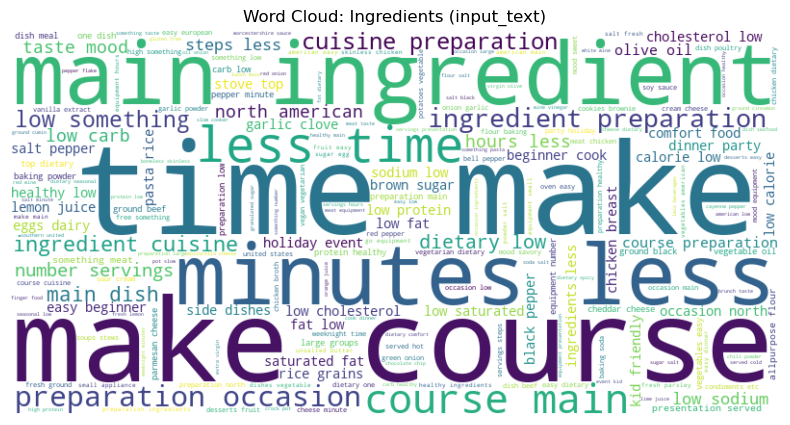

In [7]:
# Word Cloud for ingredients
plt.figure(figsize=(10, 5))
wc = WordCloud(width=800, height=400, background_color='white').generate(" ".join(input_words))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud: Ingredients (input_text)")
plt.show()


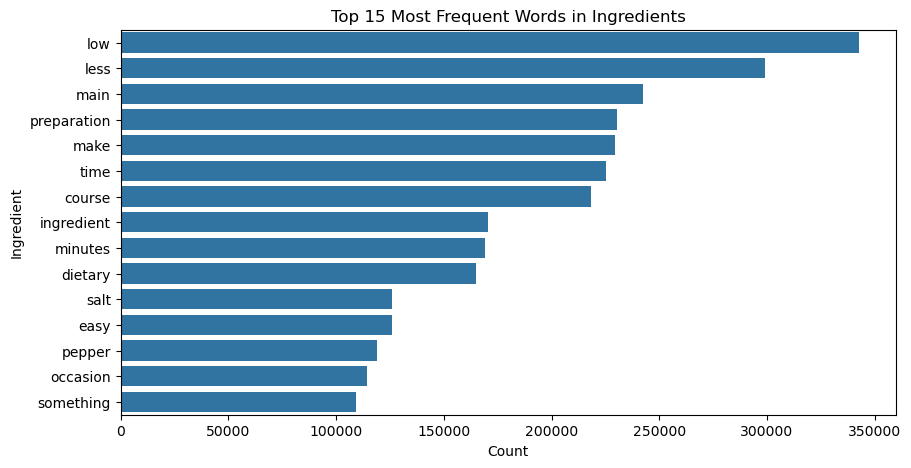

In [8]:

# Top 15 ingredients
top_input = pd.DataFrame(input_freq.most_common(15), columns=['Ingredient', 'Count'])
plt.figure(figsize=(10,5))
sns.barplot(data=top_input, x='Count', y='Ingredient')
plt.title("Top 15 Most Frequent Words in Ingredients")
plt.xlabel("Count")
plt.ylabel("Ingredient")
plt.show()

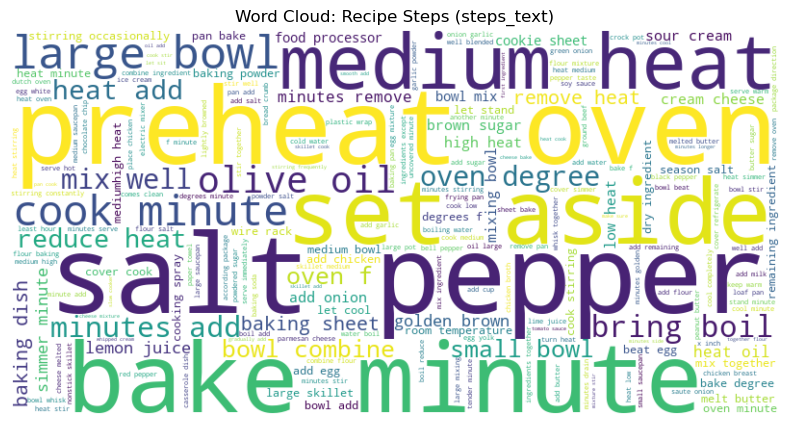

In [9]:
# Word Cloud for steps
plt.figure(figsize=(10, 5))
wc = WordCloud(width=800, height=400, background_color='white').generate(" ".join(steps_words))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud: Recipe Steps (steps_text)")
plt.show()

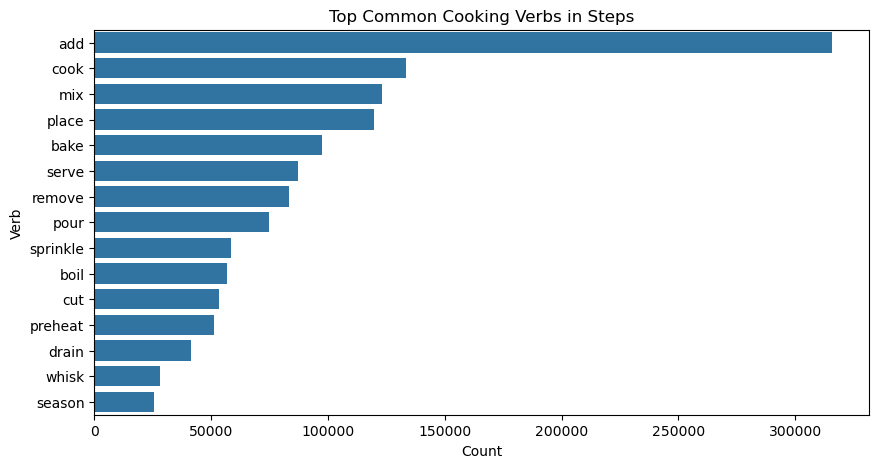

In [10]:

# Top 15 cooking actions (verbs)
common_verbs = ['add', 'bake', 'boil', 'cook', 'cut', 'drain', 'mix', 'place', 'pour', 'preheat', 'remove', 'season', 'serve', 'sprinkle', 'whisk']
verb_counts = {verb: steps_words.count(verb) for verb in common_verbs}
top_verbs = pd.DataFrame(sorted(verb_counts.items(), key=lambda x: x[1], reverse=True), columns=['Verb', 'Count'])

plt.figure(figsize=(10,5))
sns.barplot(data=top_verbs, x='Count', y='Verb')
plt.title("Top Common Cooking Verbs in Steps")
plt.xlabel("Count")
plt.ylabel("Verb")
plt.show()

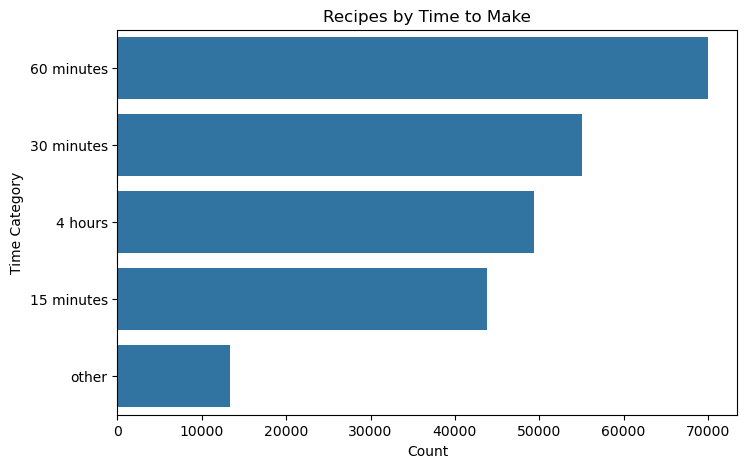

In [11]:
# Further EDA: Ingredient uniqueness, shared terms, and "time to make" analysis

# 1. Total unique ingredients (after cleaning)
unique_ingredients = set(input_words)
unique_steps_words = set(steps_words)

# 2. Words shared between input and steps
common_words = unique_ingredients.intersection(unique_steps_words)

# 3. Time-based tag extraction
def extract_time_tag(text):
    matches = re.findall(r"\d+\s+minutes|\d+\s+hours", text)
    return matches[0] if matches else "other"

df['time_tag'] = df['input_text'].apply(extract_time_tag)

# 4. Count of recipes by time tag
time_tag_counts = df['time_tag'].value_counts().reset_index()
time_tag_counts.columns = ['Time Category', 'Recipe Count']

# Plot recipes by time to make
plt.figure(figsize=(8, 5))
sns.barplot(data=time_tag_counts, x='Recipe Count', y='Time Category')
plt.title("Recipes by Time to Make")
plt.xlabel("Count")
plt.ylabel("Time Category")
plt.show()




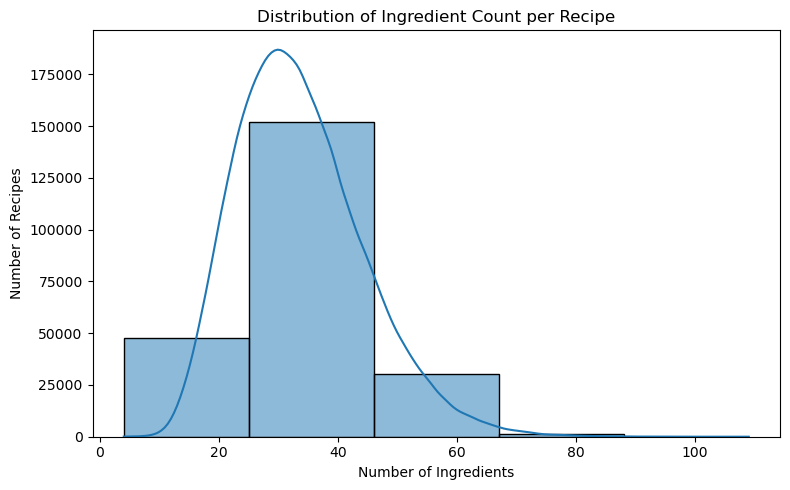

In [17]:
# 2. Distribution of ingredient length per recipe
df['ingredient_count'] = df['filtered_input'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
sns.histplot(df['ingredient_count'], bins=5, kde=True)
plt.title("Distribution of Ingredient Count per Recipe")
plt.xlabel("Number of Ingredients")
plt.ylabel("Number of Recipes")
plt.tight_layout()
plt.show()


- Most recipes contain 25 to 40 ingredients, forming a sharp peak in that range.
- The distribution is right-skewed, with a few recipes using 60+ ingredients, which may be rare or overly descriptive.
- Helps classify recipes as simple (≤25), moderate (25–40), or complex (≥50) — useful for difficulty-level tagging or user filtering.


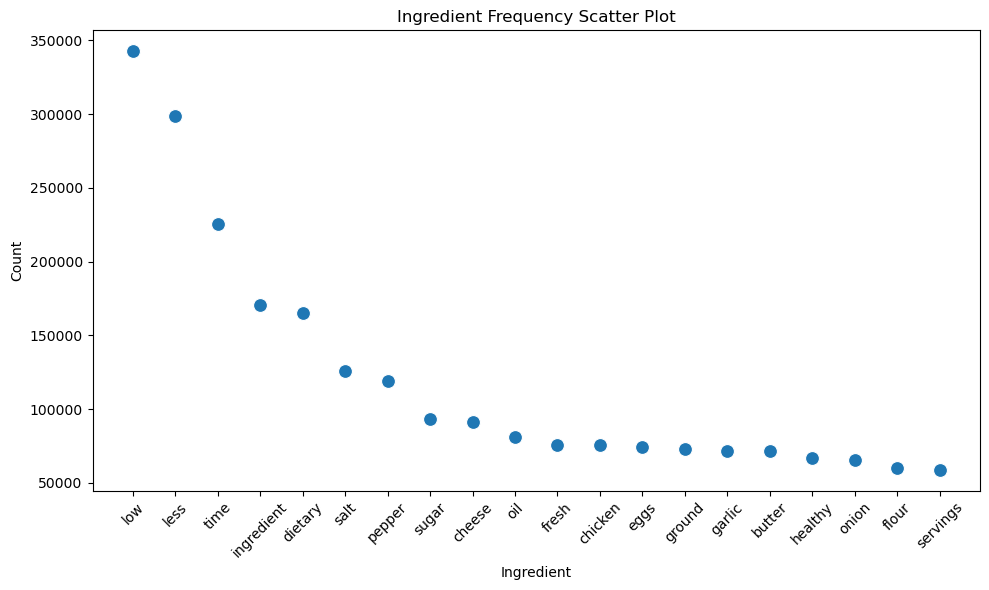

In [18]:
# 3. Word frequency scatter plot (top 20)
top_20 = pd.DataFrame(ingredient_counts.most_common(20), columns=["Ingredient", "Count"])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=top_20, x="Ingredient", y="Count", s=100)
plt.title("Ingredient Frequency Scatter Plot")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A quick-glance comparison of how often top ingredients occur.
Common pantry items like low, less, salt, pepper, and oil dominate the dataset.
There’s a sharp drop after top items, showing a long tail of unique ingredients — great for pantry-to-recipe personalization.

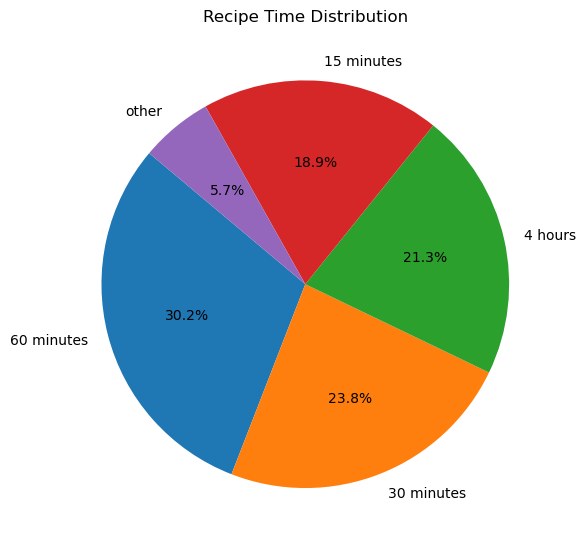

In [19]:
# 4. Pie chart of time tags
time_dist = df['time_tag'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(time_dist.values, labels=time_dist.index, autopct='%1.1f%%', startangle=140)
plt.title("Recipe Time Distribution")
plt.tight_layout()
plt.show()


Most recipes fall into 60 minutes (30.2%), 30 minutes (23.8%), and 4 hours (21.3%) categories.
This allows for filtering by user time availability and optimizing recipe suggestions accordingly.

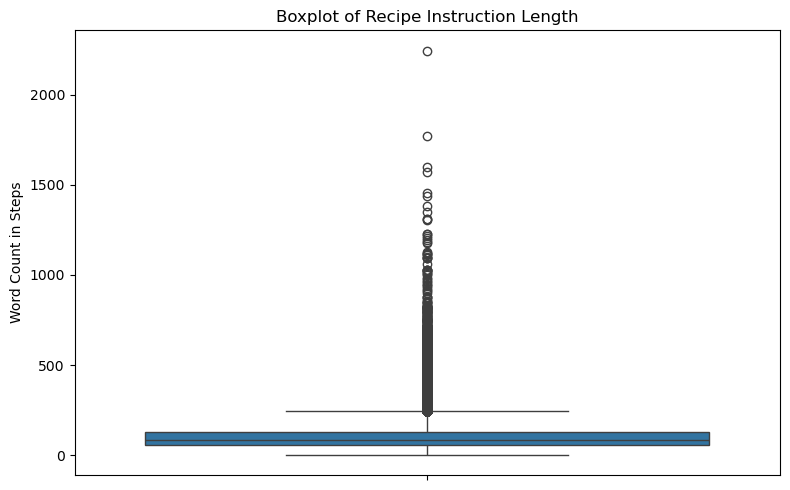

In [20]:
# 5. Boxplot: steps length distribution
df['steps_len'] = df['steps_text'].apply(lambda x: len(x.split()))
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='steps_len')
plt.title("Boxplot of Recipe Instruction Length")
plt.ylabel("Word Count in Steps")
plt.tight_layout()
plt.show()


Most recipes have instructions between 50–250 words, which is a reasonable length for user readability.
There are many outliers above 500 and even beyond 2000 words, indicating a few very detailed recipes — ideal for filtering or summarization features in your app.
The median lies around 120 words, reflecting a balanced average instructional complexity.
This chart is useful for:

Detecting instruction-heavy recipes (might overwhelm users)
Applying cutoffs for LSTM sequence length when training on recipe steps.


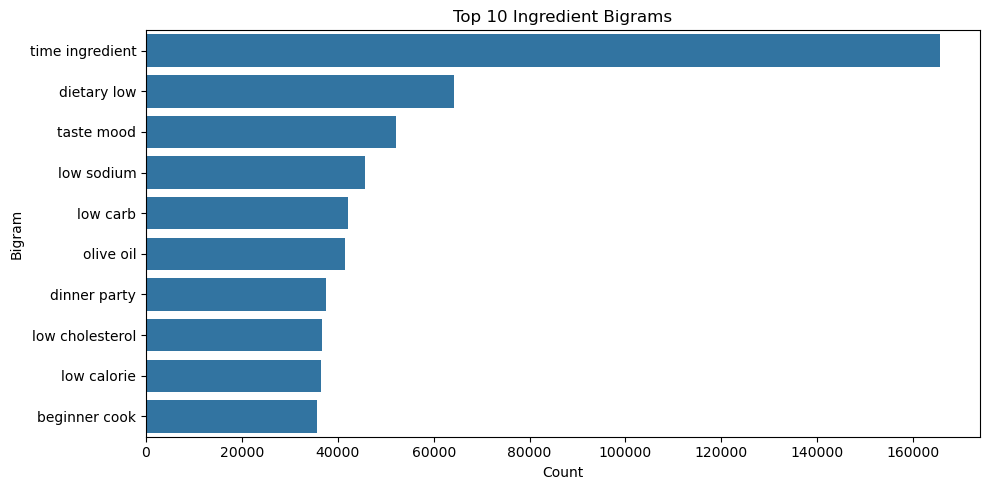

In [21]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

# 1. Ingredient bigrams
vectorizer_ing_bigram = CountVectorizer(ngram_range=(2, 2), stop_words='english')
X_ing_bigram = vectorizer_ing_bigram.fit_transform(df['filtered_input'])
sum_words_ing = X_ing_bigram.sum(axis=0)
ing_bigram_freq = [(word, sum_words_ing[0, idx]) for word, idx in vectorizer_ing_bigram.vocabulary_.items()]
sorted_ing_bigrams = sorted(ing_bigram_freq, key=lambda x: x[1], reverse=True)[:10]
df_ing_bigrams = pd.DataFrame(sorted_ing_bigrams, columns=["Bigram", "Count"])

plt.figure(figsize=(10, 5))
sns.barplot(data=df_ing_bigrams, y="Bigram", x="Count")
plt.title("Top 10 Ingredient Bigrams")
plt.tight_layout()
plt.show()

- Most frequent bigrams like time ingredient, dietary low, low sodium, and low carb reflect dietary tags and metadata, not core ingredients.
- Olive oil stands out as a true culinary ingredient, whereas phrases like beginner cook and dinner party relate to user context or occasion.
- This indicates that the input_text field mixes ingredient data with descriptive tags, so it’s crucial to separate metadata from ingredients for modeling or pantry matching.

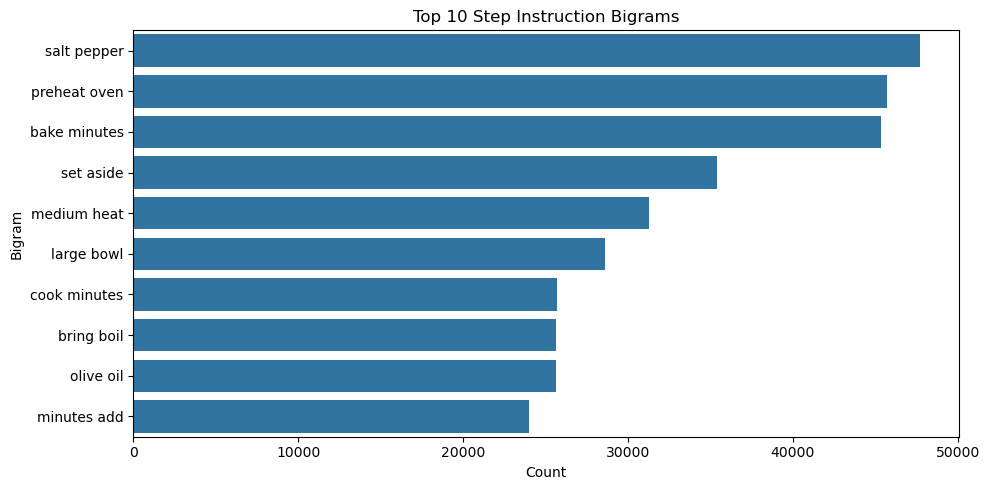

In [22]:
# 2. Step bigrams
vectorizer_step_bigram = CountVectorizer(ngram_range=(2, 2), stop_words='english')
X_step_bigram = vectorizer_step_bigram.fit_transform(df['clean_steps'])
sum_words_step = X_step_bigram.sum(axis=0)
step_bigram_freq = [(word, sum_words_step[0, idx]) for word, idx in vectorizer_step_bigram.vocabulary_.items()]
sorted_step_bigrams = sorted(step_bigram_freq, key=lambda x: x[1], reverse=True)[:10]
df_step_bigrams = pd.DataFrame(sorted_step_bigrams, columns=["Bigram", "Count"])

plt.figure(figsize=(10, 5))
sns.barplot(data=df_step_bigrams, y="Bigram", x="Count")
plt.title("Top 10 Step Instruction Bigrams")
plt.tight_layout()
plt.show()

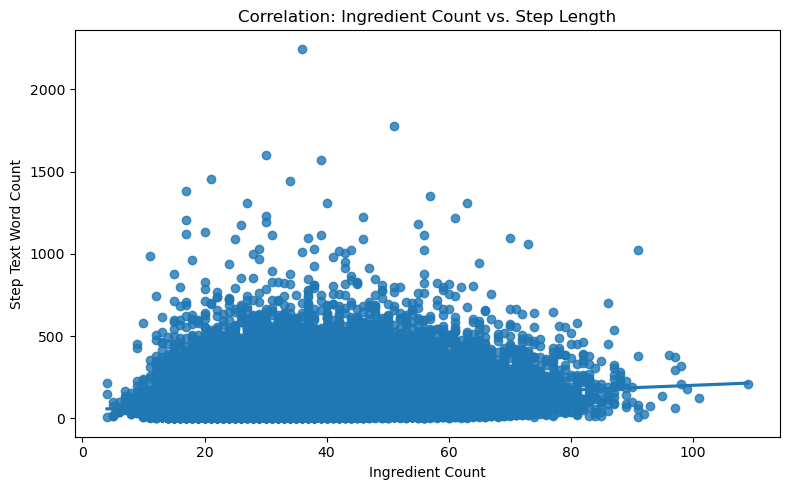

In [23]:
# 3. Correlation: Ingredient count vs. Step length
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='ingredient_count', y='steps_len')
plt.title("Correlation: Ingredient Count vs. Step Length")
plt.xlabel("Ingredient Count")
plt.ylabel("Step Text Word Count")
plt.tight_layout()
plt.show()

- The scatter plot shows weak or no strong correlation between the number of ingredients and the step length.
- Some recipes with few ingredients still have very long instructions, likely due to detailed cooking methods or storytelling formats.
- This highlights that recipe complexity ≠ number of ingredients — important for building accurate recipe difficulty estimators or LSTM input lengths.

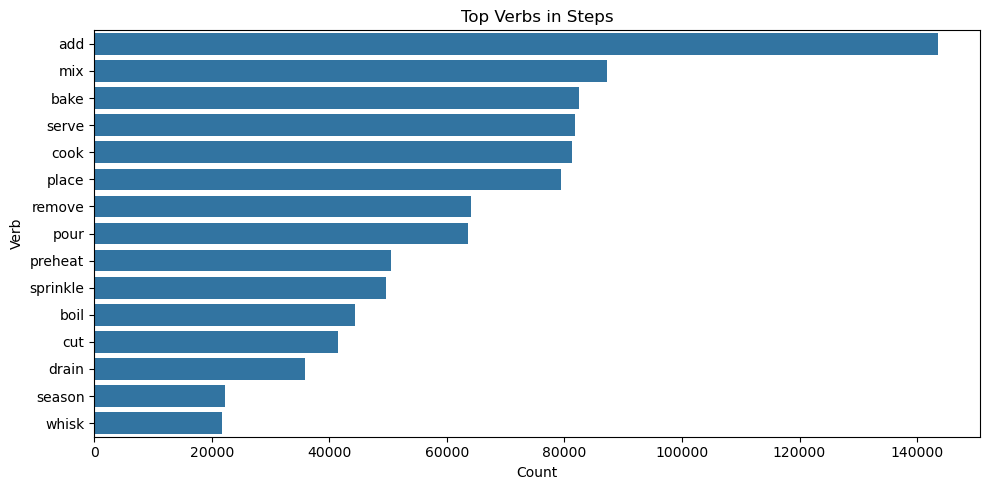

In [24]:
# 4. Top Verbs in steps
verbs = ['add', 'bake', 'boil', 'cook', 'cut', 'drain', 'mix', 'place', 'pour', 'preheat', 'remove', 'season', 'serve', 'sprinkle', 'whisk']
verb_counts = {verb: sum(verb in step.split() for step in df['clean_steps']) for verb in verbs}
df_verbs = pd.DataFrame(verb_counts.items(), columns=["Verb", "Count"]).sort_values("Count", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=df_verbs, y="Verb", x="Count")
plt.title("Top Verbs in Steps")
plt.tight_layout()
plt.show()

- The most common verbs are add, mix, and bake, which dominate instruction language.
- This indicates that most recipes follow a mix-then-cook pattern, suggesting a general cooking structure.
- These verbs are valuable for LSTM model vocabularies, action extraction, or creating step templates.

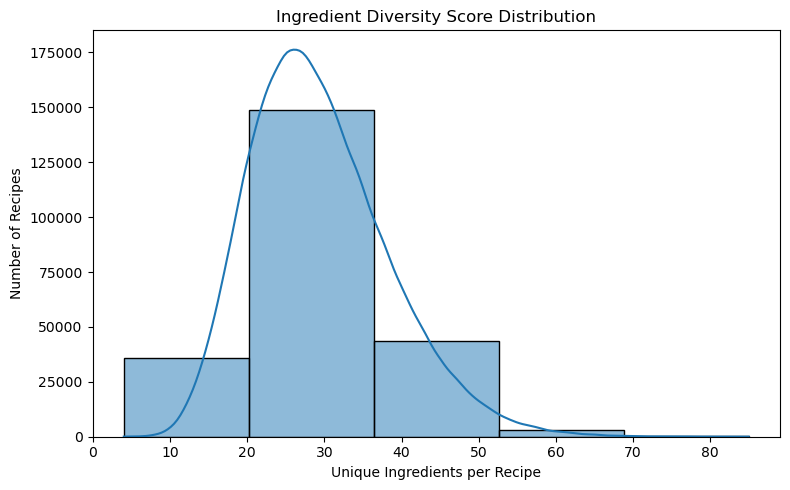

In [25]:
# 5. Ingredient Diversity Score (unique word count per recipe)
df['ingredient_diversity'] = df['filtered_input'].apply(lambda x: len(set(x.split())))

plt.figure(figsize=(8, 5))
sns.histplot(df['ingredient_diversity'], bins=5, kde=True)
plt.title("Ingredient Diversity Score Distribution")
plt.xlabel("Unique Ingredients per Recipe")
plt.ylabel("Number of Recipes")
plt.tight_layout()
plt.show()


- Most recipes use 20–35 unique ingredients, which balances diversity and simplicity.
- Very few recipes exceed 50+ unique ingredients, making them outliers or potentially noisy.
- This metric is useful for defining recipe complexity and guiding minimalist meal recommendations.